# Assignment 2
## Group A: Polynomial Regression
### Ivan Bibat
#### L00167791@atu.ie

## What is polynomial regression ?
Polynomial regression is a form of linear regression where the relationship between the independent variable x and dependent variable y are modeled as an nth order polynomial.

Polynomial regression fits a non-linear relationship between the value of x and the corresponding conditional mean of y.

1. Install required dependencies

In [ ]:
%pip install numpy pandas fasteda adtk

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached matplotlib-3.11.2-cp315-cp315-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp315-cp315-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp315-cp315-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp315-cp315-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 17.2 MB/s  0:00:00eta 0:00:01
Using cached matplotlib-3.11.2-cp315-cp315-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp315-cp315-macosx_11_0_arm64.whl (283 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3

2. Import necessary packages

In [5]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
from fasteda import fast_eda
import matplotlib.pyplot as plt
import seaborn as sns
from adtk.detector import InterQuartileRangeAD
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import make_pipeline

3. Read the data

In [12]:
df = pd.read_csv("/Users/ivanbibat/Documents/GitHub/machine-learning-notebooks/data/co2_mm_mlo.csv", comment = "#")

In [ ]:
# Display basic information about the dataset
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 823 entries, 0 to 822
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   year            823 non-null    int64  
 1   month           823 non-null    int64  
 2   decimal date    823 non-null    float64
 3   average         823 non-null    float64
 4   deseasonalized  823 non-null    float64
 5   ndays           823 non-null    int64  
 6   sdev            823 non-null    float64
 7   unc             823 non-null    float64
dtypes: float64(5), int64(3)
memory usage: 51.6 KB
None


In [ ]:
# Summary statistics for numerical columns
print(df.describe())

              year       month  decimal date     average  deseasonalized  \
count   823.000000  823.000000    823.000000  823.000000      823.000000   
mean   1991.958688    6.495747   1992.457736  361.439101      361.431786   
std      19.812337    3.444685     19.811122   33.511832       33.451725   
min    1958.000000    1.000000   1958.202700  312.420000      314.440000   
25%    1975.000000    4.000000   1975.333350  331.285000      330.915000   
50%    1992.000000    6.000000   1992.458300  356.380000      356.500000   
75%    2009.000000    9.000000   2009.583350  387.845000      387.825000   
max    2026.000000   12.000000   2026.708300  432.340000      429.550000   

            ndays        sdev         unc  
count  823.000000  823.000000  823.000000  
mean    19.165249   -1.991592   -0.084593  
std     11.810524    4.478122    0.508127  
min     -1.000000   -9.990000   -0.990000  
25%     14.500000    0.210000    0.080000  
50%     25.000000    0.400000    0.150000  
75%    

In [ ]:
# Check for missing values in the dataset
print(df.isnull().sum())

year              0
month             0
decimal date      0
average           0
deseasonalized    0
ndays             0
sdev              0
unc               0
dtype: int64


In [20]:

df[["ndays", "sdev", "unc"]] = df[["ndays", "sdev", "unc"]].mask(df[["ndays", "sdev", "unc"]] < 0, np.nan)

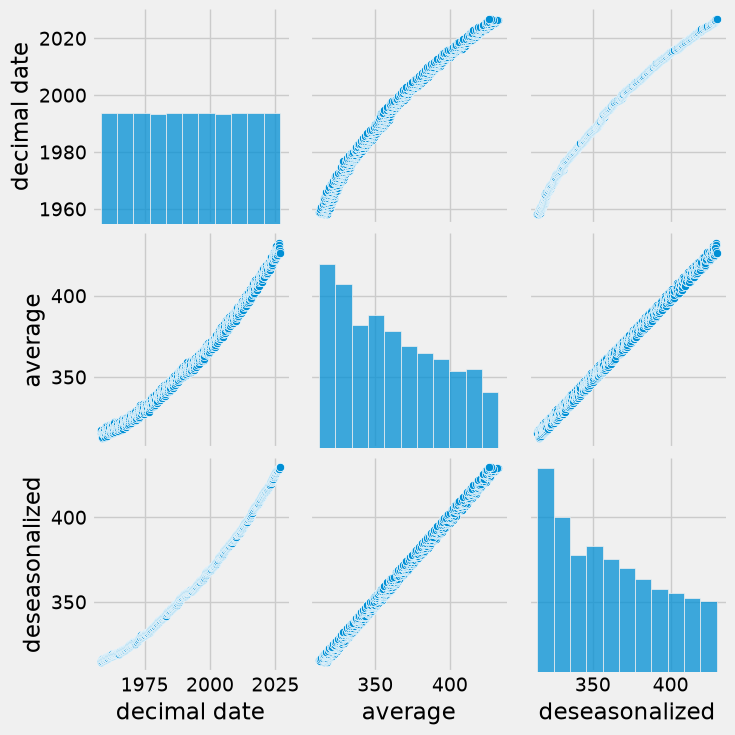

In [22]:
sns.pairplot(
    df,  
    vars=
    [
        "decimal date",
        "average",
        "deseasonalized",
    ]
)
plt.show()

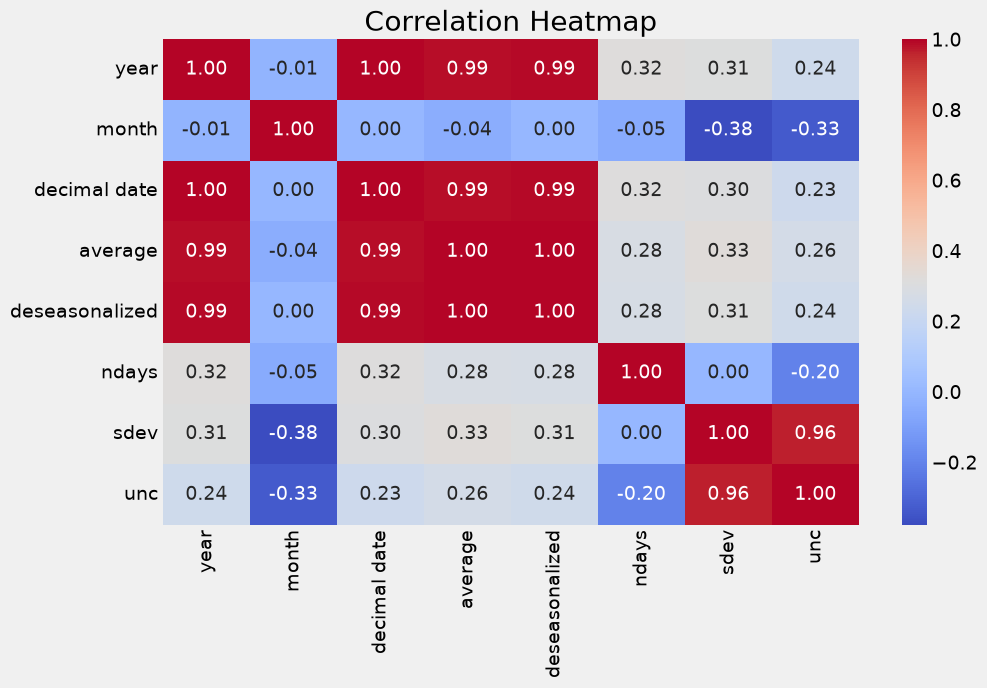

In [ ]:
cols = ["ndays", "sdev", "unc"]
df[cols] = df[cols].mask(df[cols] < 0, np.nan)

correlation_matrix = df.corr()
plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()